In [ ]:
import numpy as np
import pandas as pd 
import seaborn as sns
import pywt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("C:/Data/accelerometer.csv")
data = df[['x', 'y', 'z']]
data.head()

,x,y,z
0,1.004,0.090,-0.125
1,1.004,-0.043,-0.125
2,0.969,0.090,-0.121
3,0.973,-0.012,-0.137
4,1.000,-0.016,-0.121


In [ ]:
def create_windows(data, window_size=128, step=64):
    windows = []
    for i in range(0, len(data) - window_size, step):
        windows.append(data.iloc[i:i+window_size].values)
    return np.array(windows)

windows = create_windows(data)
print("Windows shape:", windows.shape)

Windows shape: (2389, 128, 3)


In [ ]:
def extract_features(windows):
    features = []
    for w in windows:
        feat = []
        for i in range (w.shape[1]):
            signal = w[:, i]

            mean = np.mean(signal)
            std = np.std(signal)
            max_val = np.max(signal)
            min_val = np.min(signal)
            rms = np.sqrt(np.mean(signal**2))

            fft_vals = np.abs(np.fft.fft(signal))
            fft_mean = np.mean(fft_vals)
            fft_max = np.max(fft_vals)

            coeffs = pywt.wavedec(signal, 'db4', level=3)
            wavelet_energy = sum(np.sum(c**2) for c in coeffs)

            feat.extend([mean, std, max_val, min_val, rms, fft_mean, fft_max, wavelet_energy])
        features.append(feat)
    return np.array(features)

X = extract_features(windows)

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
model = IsolationForest(n_estimators=200, contamination=0.05, random_state=42)
model.fit(X_scaled)

,n_estimators,200
,max_samples,'auto'
,contamination,0.05
,max_features,1.0
,bootstrap,False
,n_jobs,None
,random_state,42
,verbose,0
,warm_start,False


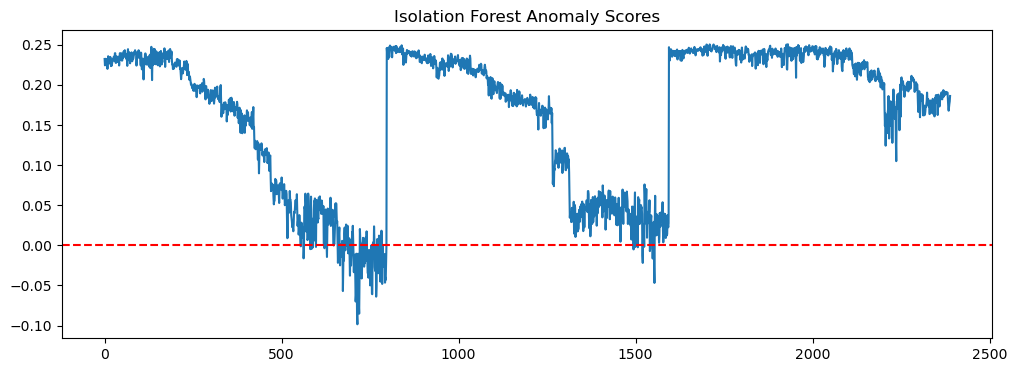

In [ ]:
preds = model.predict(X_scaled)
scores = model.decision_function(X_scaled)

plt.figure(figsize=(12, 4))
plt.plot(scores)
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Isolation Forest Anomaly Scores")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy: ", accuracy)